# Import The Library 

In [40]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score



# Load The Dataset

In [2]:
# Read the dataseet 
dataset = pd.read_csv(r"Dataset/Salary_dataset.csv",index_col=0)

In [3]:
# Shape of the dataset 
print(f"Shape of the dataset: {dataset.shape[0]} rows, {dataset.shape[1]} columns")
print(f"Columns: {list(dataset.columns)}")

Shape of the dataset: 30 rows, 2 columns
Columns: ['YearsExperience', 'Salary']


In [4]:
dataset.head(5)

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [5]:
dataset.sample(5)

,YearsExperience,Salary
11,4.1,55795.0
19,6.1,93941.0
29,10.6,121873.0
6,3.1,60151.0
13,4.2,57082.0


# Data Description

In [6]:
# print Basic information of dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 720.0 bytes


In [7]:
# Now we are going to show null value and duplication value 
print("Null values in each features : \n",dataset.isnull().sum())
print("Overall Null values in dataset: \n", dataset.isnull().sum().sum())
print("Duplicates value in each features: \n", dataset.duplicated().sum())
print("Overall duplicate value in dataset: \n",dataset.duplicated().sum().sum())

Null values in each features : 
 YearsExperience    0
Salary             0
dtype: int64
Overall Null values in dataset: 
 0
Duplicates value in each features: 
 0
Overall duplicate value in dataset: 
 0


In [8]:
# Descriptive statistics 
dataset.describe().round(2)

,YearsExperience,Salary
count,30.00,30.00
mean,5.41,76004.00
std,2.84,27414.43
min,1.20,37732.00
25%,3.30,56721.75
50%,4.80,65238.00
75%,7.80,100545.75
max,10.60,122392.00


# EDA

### Distribution of each values 

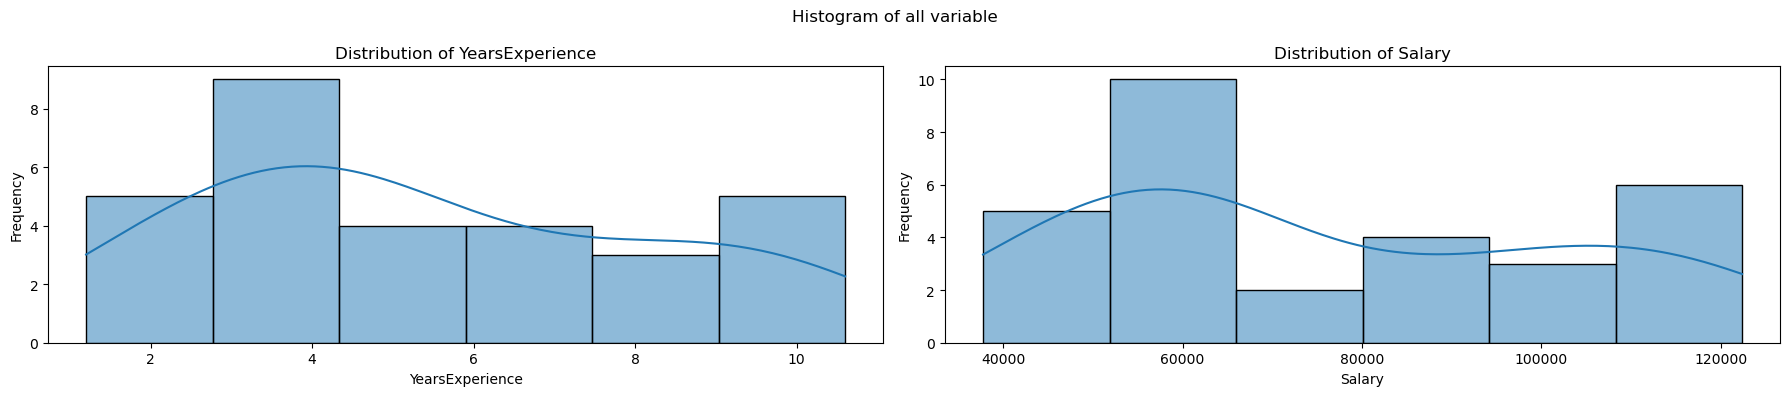

In [9]:
fig , axes = plt.subplots(1,2,figsize=(18,4))
for i, col in enumerate(dataset.columns):
    sns.histplot(dataset[col],kde=True,ax = axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
plt.suptitle("Histogram of all variable")
plt.tight_layout()
plt.show()

### Boxplot -- Spotting outliner

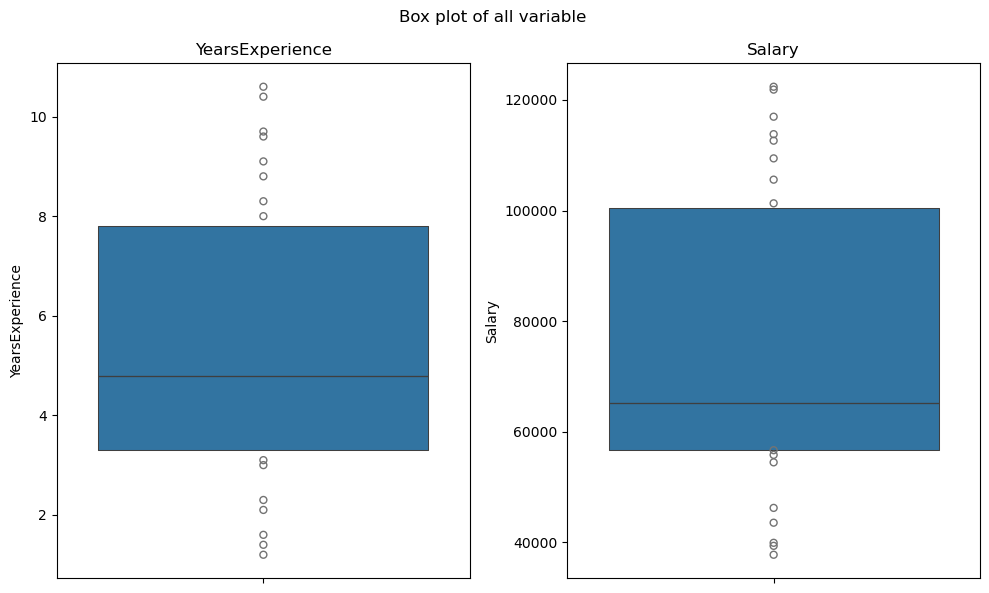

In [10]:
fig , axes = plt.subplots(1,2,figsize = (10,6))
for i,col in enumerate(dataset.columns):
    sns.boxenplot(dataset[col],ax = axes[i])
    axes[i].set_title(f"{col}")
    axes[i].set_ylabel(f"{col}")
plt.suptitle("Box plot of all variable ")
plt.tight_layout()
plt.show()

## handling outlier 

In [11]:
print(dataset.sort_values(by="Salary", ascending=False).head(10))

    YearsExperience    Salary
28             10.4  122392.0
29             10.6  121873.0
26              9.6  116970.0
23              8.3  113813.0
27              9.7  112636.0
24              8.8  109432.0
25              9.1  105583.0
22              8.0  101303.0
21              7.2   98274.0
19              6.1   93941.0


In [12]:
print(dataset.sort_values(by="Salary", ascending=True).head(10))

    YearsExperience   Salary
2               1.6  37732.0
0               1.2  39344.0
4               2.3  39892.0
3               2.1  43526.0
1               1.4  46206.0
7               3.3  54446.0
11              4.1  55795.0
5               3.0  56643.0
12              4.1  56958.0
13              4.2  57082.0


In [13]:
dataset.sort_values(by='YearsExperience').head(10)

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0
5,3.0,56643.0
6,3.1,60151.0
7,3.3,54446.0
8,3.3,64446.0
9,3.8,57190.0


### **Summary: Outlier Analysis**

* **Data Inspection:** Examined the extreme ends of the dataset by sorting the `Salary` column in both descending and ascending orders[cite: 3].
* **Logical Validation:** The sorted values are entirely genuine and realistic (e.g., 10.4–10.6 years of experience correspond to higher salaries $\approx \$121,000 - \$122,000$, while 1.2–1.6 years correspond to entry-level salaries $\approx \$37,000 - \$39,000$)[cite: 3].
* **Conclusion:** These values reflect the natural spread between junior and senior roles in a real-world workforce rather than being typos or data entry errors.
* **Final Recommendation:** **Do not remove these data points.** Deleting them would remove critical high-end patterns for senior employees, negatively impacting your machine learning model's training accuracy.

In [14]:
dataset.columns

Index(['YearsExperience', 'Salary'], dtype='object')

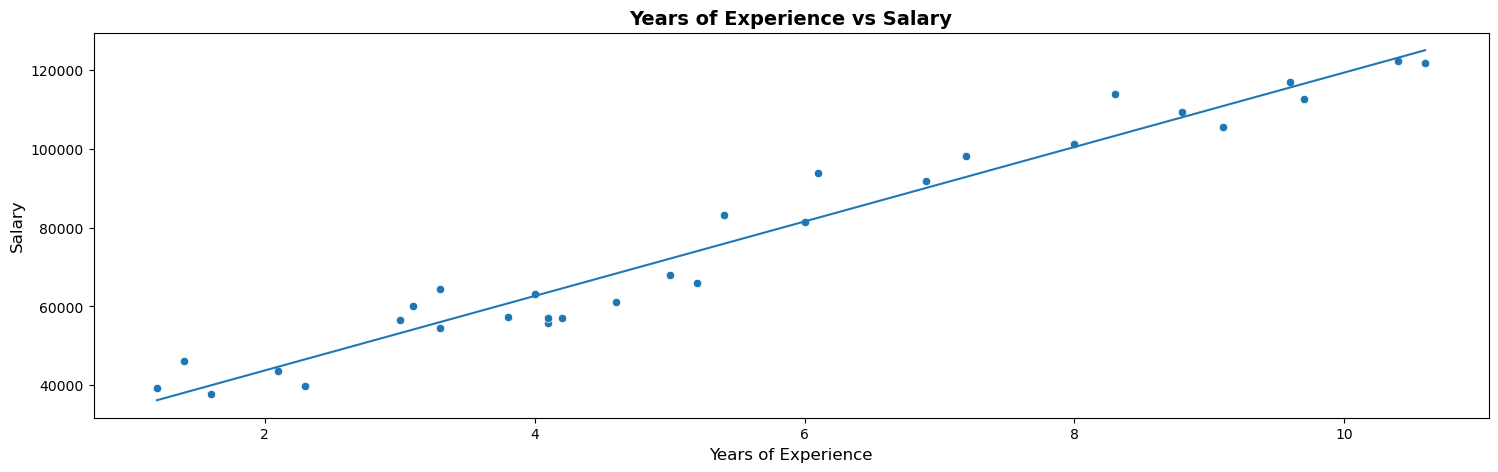

In [15]:
## scatter plots -- feature vs salary 
fig , axes = plt.subplots(1,1,figsize = (18,5))
sns.scatterplot(x = dataset['YearsExperience'], y = dataset['Salary'],axes = axes)

axes.set_title('Years of Experience vs Salary', fontsize=14, fontweight='bold')
axes.set_xlabel('Years of Experience', fontsize=12)
axes.set_ylabel('Salary', fontsize=12)
#draw best fit line 
z = np.polyfit(dataset['YearsExperience'],dataset['Salary'],1)
p = np.poly1d(z)
x_line = np.linspace(dataset['YearsExperience'].min() , dataset['YearsExperience'].max(),100)
axes.plot(x_line,p(x_line))

plt.show()

In [16]:
## correlation matrix 
corr = dataset.corr().round(2)
print(corr)

                 YearsExperience  Salary
YearsExperience             1.00    0.98
Salary                      0.98    1.00


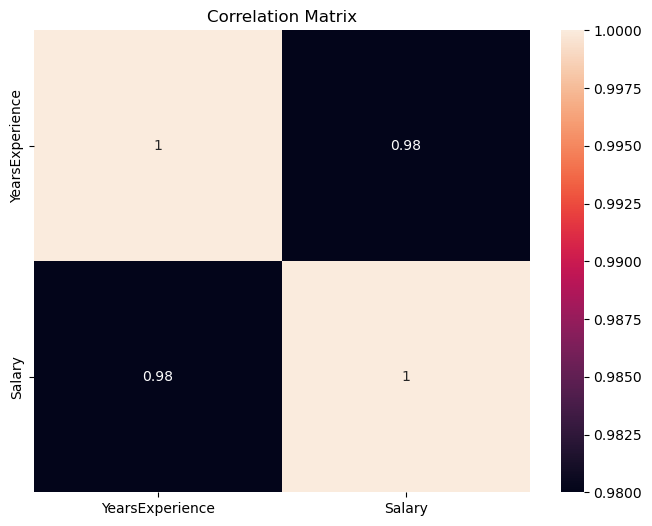

In [17]:
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True)
plt.title("Correlation Matrix")
plt.show()

## Prepare the data for Modeling

In [20]:
x = dataset.drop(columns = ['Salary'])
y = dataset['Salary'].values

In [23]:
x_train,x_test, y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
# now print the training and test size 

print(f"Traing set size: {x_train.shape[0]} Samples")
print(f"Test set Size : {x_test.shape[0]} Samples")

Traing set size: 24 Samples
Test set Size : 6 Samples


# Build The Model

In [25]:
slr = LinearRegression()
slr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9423.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.438e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [26]:
# Now print the coef of model 
print(f"Intercept : {slr.intercept_:}")
print(f"Slope: {slr.coef_[0]}")

Intercept : 24380.201479473704
Slope: 9423.815323030976


In [27]:
# Equation of Line 

print(f"Equation : Salary = {slr.coef_[0]:.2f} * YearsExperience + {slr.intercept_:.2f}")

Equation : Salary = 9423.82 * YearsExperience + 24380.20


# Predict the Value 

In [28]:
y_pred = slr.predict(x_test)

In [29]:
y_pred

array([115791.21011287,  71499.27809463, 102597.86866063,  75268.80422384,
        55478.79204548,  60190.69970699])

In [30]:
dat = pd.DataFrame(
    {
        "Actual Value " : y_test,
        "Predicted Value " : y_pred
    }
)

print(dat)

   Actual Value   Predicted Value 
0       112636.0     115791.210113
1        67939.0      71499.278095
2       113813.0     102597.868661
3        83089.0      75268.804224
4        64446.0      55478.792045
5        57190.0      60190.699707


/home/parmanand/Desktop/full _stack_datascience/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


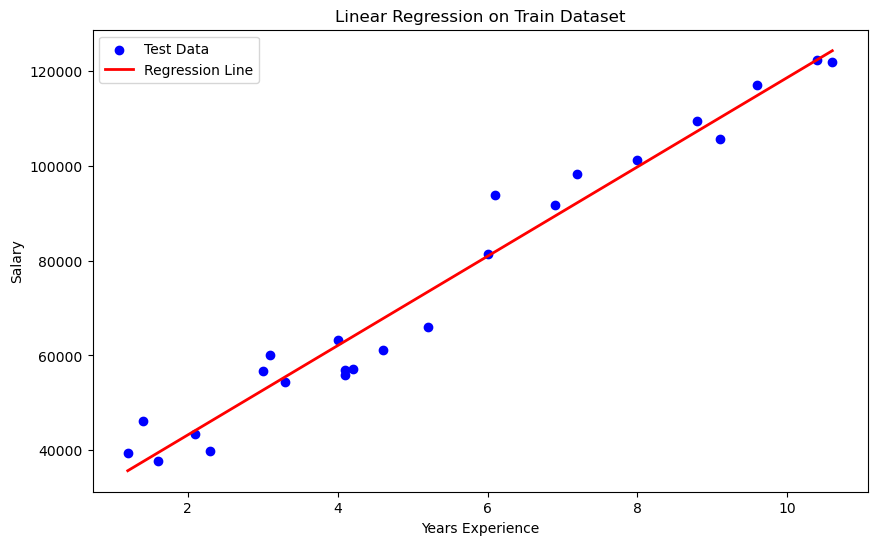

In [36]:

# Visualization of linear regression on train dataset
plt.figure(figsize=(10, 6))

plt.scatter(x_train, y_train, color='blue', label='Test Data')

x_range = np.linspace(x_train.min(), x_train.max(), 100)

#  convert x_range into 2d  by using  (.reshape(-1, 1) )
plt.plot(
    x_range,
    slr.predict(x_range.reshape(-1, 1)),
    color='red',
    linewidth=2,
    label='Regression Line',
)

plt.xlabel('Years Experience')
plt.ylabel('Salary')
plt.title('Linear Regression on Train Dataset')
plt.legend()
plt.show()

/home/parmanand/Desktop/full _stack_datascience/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


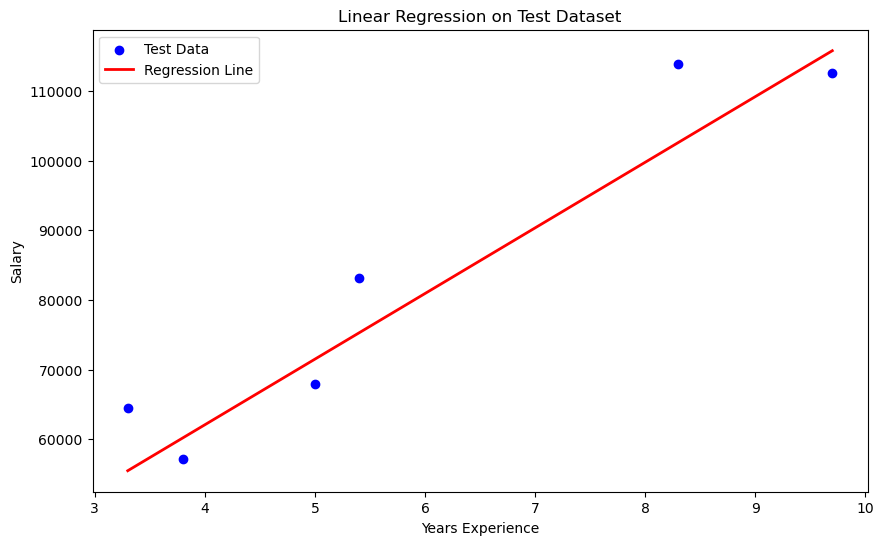

In [35]:

# Visualization of linear regression on test dataset
plt.figure(figsize=(10, 6))

plt.scatter(x_test, y_test, color='blue', label='Test Data')

x_range = np.linspace(x_test.min(), x_test.max(), 100)

#  convert x_range into 2d  by using  (.reshape(-1, 1) )
plt.plot(
    x_range,
    slr.predict(x_range.reshape(-1, 1)),
    color='red',
    linewidth=2,
    label='Regression Line',
)

plt.xlabel('Years Experience')
plt.ylabel('Salary')
plt.title('Linear Regression on Test Dataset')
plt.legend()
plt.show()

# Model evaluation 

In [38]:
y_pred

array([115791.21011287,  71499.27809463, 102597.86866063,  75268.80422384,
        55478.79204548,  60190.69970699])

In [39]:
y_test

array([112636.,  67939., 113813.,  83089.,  64446.,  57190.])

In [41]:
print("Mean absolute  Error : \n")
print(mean_absolute_error(y_test,y_pred))

Mean absolute  Error : 

6286.453830757745


In [42]:
print("Mean Square Error")
print(mean_squared_error(y_test,y_pred))

Mean Square Error
49830096.855908394


In [44]:
print("Root Mean Square Error")
print(root_mean_squared_error(y_test,y_pred))


Root Mean Square Error
7059.04362190151


In [46]:
print("R2 Score")

print(r2_score(y_test,y_pred))

R2 Score
0.9024461774180497


In [48]:
dataset.shape

(30, 2)

In [50]:
print("Adjusted R2 Score")
r2 = r2_score(y_test,y_pred)
n = dataset.shape[0]
k = dataset.shape[1]
adr2 = 1 -( ((1-r2)*(n - 1))/ (n-k-1)   )
print(adr2)

Adjusted R2 Score
0.8952199683379052
